In [7]:
import matplotlib.pyplot as plt
from astropy.io import fits
import numpy as np

In [8]:
values = []
for i in range(1, 6):
    filename = f"M13_{i:04d}.fits"
    with fits.open(filename) as hdul:
        header = hdul[0].header
        data = hdul[0].data
        values.append(data)

In [9]:
values

[array([[489, 474, 519, ..., 447, 541, 519],
        [517, 508, 489, ..., 517, 490, 499],
        [500, 453, 518, ..., 537, 514, 537],
        ...,
        [449, 490, 519, ..., 469, 508, 541],
        [500, 521, 514, ..., 502, 478, 549],
        [480, 516, 535, ..., 494, 527, 491]],
       shape=(1040, 1392), dtype=uint16),
 array([[494, 529, 549, ..., 492, 535, 560],
        [540, 530, 479, ..., 484, 514, 496],
        [500, 517, 514, ..., 520, 518, 552],
        ...,
        [498, 515, 509, ..., 527, 533, 531],
        [499, 495, 505, ..., 521, 447, 541],
        [513, 541, 522, ..., 522, 521, 472]],
       shape=(1040, 1392), dtype=uint16),
 array([[517, 475, 503, ..., 515, 531, 531],
        [521, 434, 489, ..., 575, 484, 499],
        [492, 498, 516, ..., 535, 486, 512],
        ...,
        [504, 506, 515, ..., 486, 538, 518],
        [497, 536, 509, ..., 521, 485, 539],
        [560, 515, 573, ..., 520, 506, 541]],
       shape=(1040, 1392), dtype=uint16),
 array([[487, 490, 546

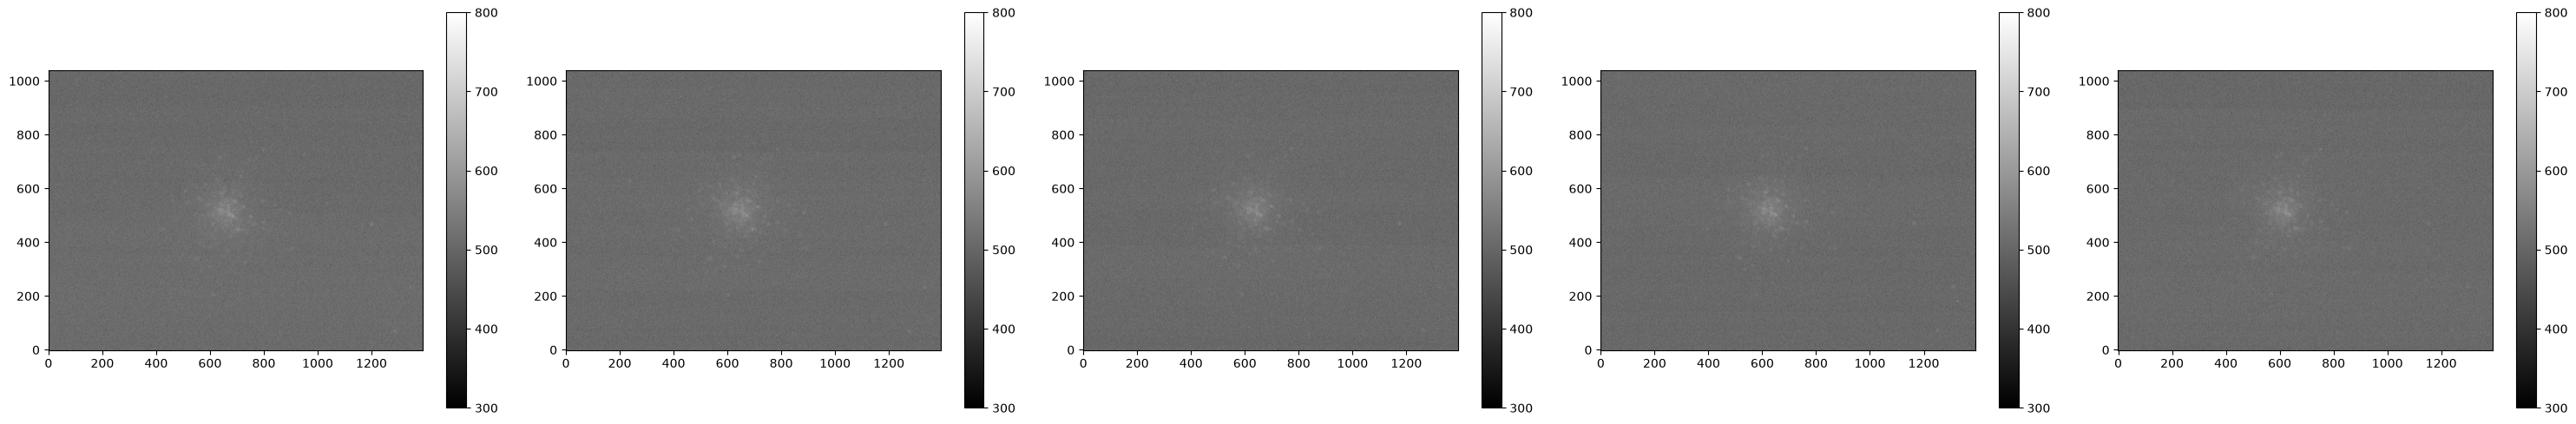

In [26]:
fig, axes = plt.subplots(1, 5, figsize=(30, 5))
im0 = axes[0].imshow(values[0], origin='lower', vmin=300, vmax=800, cmap = 'gray')
fig.colorbar(im0, ax=axes[0])
im1 = axes[1].imshow(values[1], origin='lower', vmin=300, vmax=800, cmap = 'gray')
fig.colorbar(im1, ax=axes[1])
im2 = axes[2].imshow(values[2], origin='lower', vmin=300, vmax=800, cmap = 'gray')
fig.colorbar(im2, ax=axes[2])
im3 = axes[3].imshow(values[3], origin='lower', vmin=300, vmax=800, cmap = 'gray')
fig.colorbar(im3, ax=axes[3])
im4 = axes[4].imshow(values[4], origin='lower', vmin=300, vmax=800, cmap = 'gray')
fig.colorbar(im4, ax=axes[4])
plt.tight_layout()
plt.show()

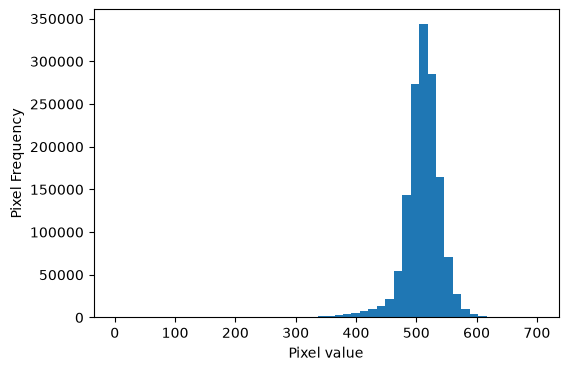

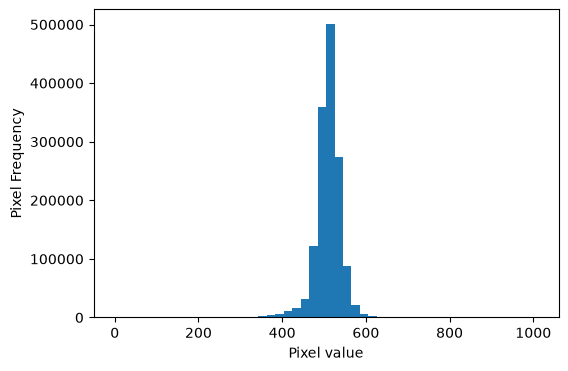

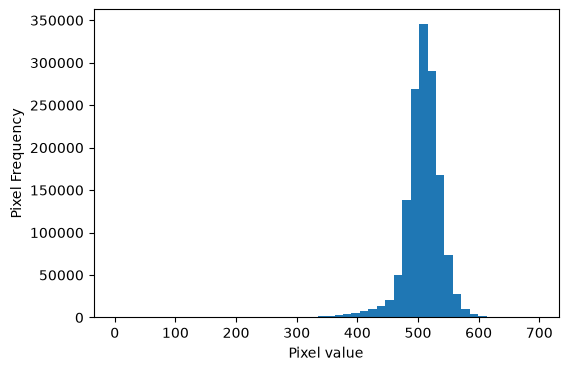

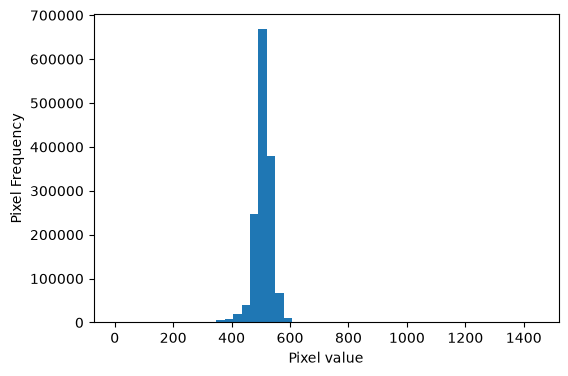

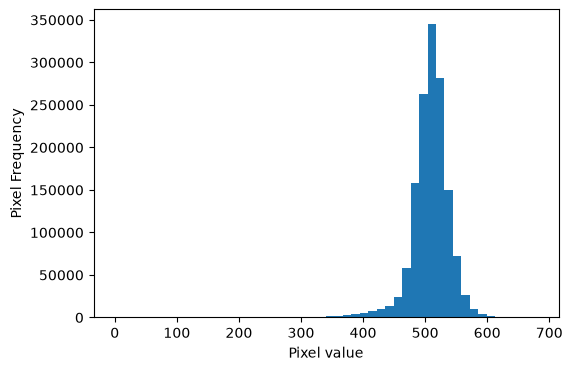

In [30]:
for i in range(len(values)):
    plt.figure(figsize=(6, 4))
    plt.hist(values[i].ravel(), bins=50)
    plt.xlabel("Pixel value")
    plt.ylabel("Pixel Frequency")
    plt.show()

In [31]:
# The x axis is the value of the pixel from the fits file. The y axis is the frequency of that value occuring. 
# Bins 50 means that there are 50 sections for the values to be categorized in. 
# Most of the daya is around 500 to 550. 
# The data is not very spread out. Most of it is between 300 and 600
for i, data in enumerate(values):
    print(np.mean(data), np.median(data))

510.4706668600796 512.0
509.7460150033157 511.0
508.0498729000884 510.0
507.90583554376656 509.0
508.7919920148099 510.0


In [35]:
combined_image = np.median(np.array(values), axis=0)
print(np.median(combined_image))

510.0


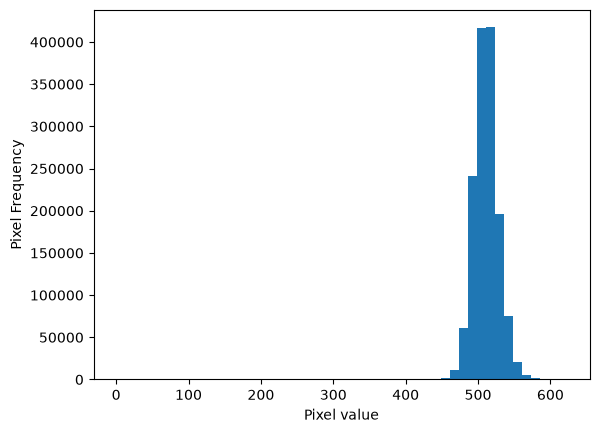

In [36]:
plt.hist(combined_image.ravel(), bins=50)
plt.xlabel("Pixel value")
plt.ylabel("Pixel Frequency")
plt.show()

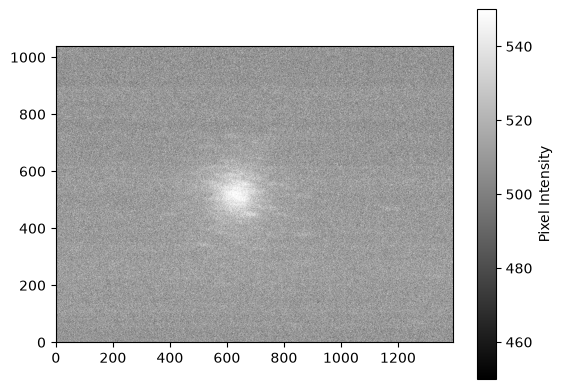

In [37]:
plt.imshow(combined_image, origin='lower', vmin=450, vmax=550, cmap='gray')
plt.colorbar(label="Pixel Intensity")
plt.show()

In [38]:
#  The image looks significantly cleaner. And it appears a little clearer.

In [39]:
fits.writeto("combined.fits", combined_image, overwrite=True)